# IPEDS Data Transformation

Joe Martin - joseph.martin@unc.edu

Last Updated 10/12/2026

## Introduction
For the past several years, I've been managing Tableau dashboards for peer university comparisons. Initially, these were simple products and I could easily copy and paste new data into a spreadsheet to manage updates. After more interest and complex requests, it's become apparent that a better data management solution is required. Other published solutions haven't held up to my needs. The APIs I've found aren't documented well enough to understand and other databases I have access to do not update regularly, quickly, or with all of the data I need. Therefore, this script is meant to simplify the data my data cleaning process to make analysis and updates easier to manage. 

What's most important to note is that this process still requires some manual process - especially in regard to downloading files. The benefit is this process greatly simplifies the current data management processes for the metrics projects, creates reproducible steps for data management and analysis, and provides greater flexibility for when we want to add new metrics or schools to our analysis. Updating data is as simple as following the four steps below: 

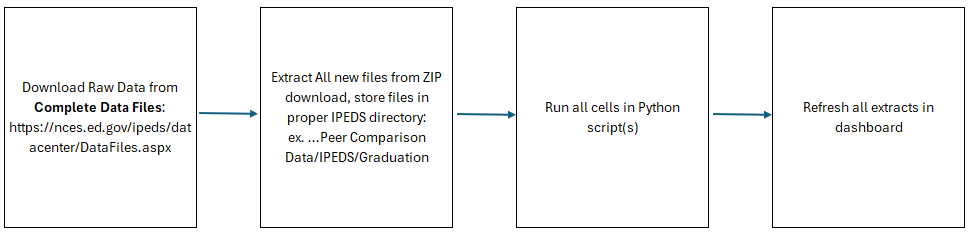

## Data File Downloads

The current dashboard uses a limited set of the IPEDS surveys to populate data. Files should be downloaded from `https://nces.ed.gov/ipeds/datacenter/DataFiles.aspx`.


### Survey Files and Availability

|   Survey   |  File  | Availability | OneDrive Folder |
|------------|--------|----------------|------|
| Graduation | GR2025 | Early Fall |.../IPEDS/Graduation/|
| Net Price | SFA/COST II | Early Fall | .../IPEDS/Net Price and Student Aid/|
| Retention | EF2025 | Mid-Fall| .../IPEDS/Enrollment/ |
| Tuition and Fees | COST I | Early Summer | .../IPEDS/Tuition and Fees/ |
| Pell Recipients | SFA/COST II | Early Fall | .../IPEDS/Net Price and Student Aid/|
| International Students | EF2025 | Mid-Fall | .../IPEDS/Enrollment/|
| Human Resources | EAP2025 | Mid-Fall | .../IPEDS/Faculty/|
| Institutional Characteristics | HD2025 | Early Summer | .../IPEDS/Institution/ |
| Finance | F2425_F1a/F2425_F2 | Mid-Fall| .../IPEDS/Finance |

**Source**: https://surveys.nces.ed.gov/ipeds/public/data-collection-schedule

### Download Process

After the files are downloaded, they should be extracted to the corresponding directory. This step is important because the script will read in files by these directory locations. 

### Data Output

After placing the IPEDS files in the proper folders, you're done! Run the script to update the output file, then refresh the extract in Tableau and upload to the server. 

# Setup
## Libraries and File Paths

In [8]:
# Set-Up
# Import librarys and set working directory

import pandas as pd
from os import listdir
from os.path import isfile, join
import numpy as np

from pyprojroot import here

wd = str(here('data/raw-data/IPEDS/')) # finds the directory with data
pub = str(here('data/processed-data/')) # location where processed data is stored


# Import value sets
value_sets = '\\Translation\\IPEDS202425Tablesdoc.xlsx'
vs = wd + value_sets

## Functions

In [10]:
def normalize_code(value):
    """
    Makes values such as 1, 1.0, and '1' comparable.
    Also trims whitespace and normalizes text capitalization.
    """
    if pd.isna(value):
        return None

    text = str(value).strip()

    try:
        number = float(text)

        if number.is_integer():
            return str(int(number))

        return str(number)

    except ValueError:
        return text.upper()


def normalize_name(value):
    """Normalizes file, table, variable, and column names."""
    if pd.isna(value):
        return None

    return str(value).strip().upper()


def replace_values(data, translation):
    """
    Replace coded values in data using translation values.

    Matching rules:
      data['file']       == translation['tablename']
      data column name   == translation['varname']
      data cell value    == translation['codevalue']

    The matching data cell is replaced with translation['valuelabel'].
    Unmatched values are preserved.
    """

    result = data.copy()
    lookup = translation.copy()

    # Normalize lookup fields
    lookup["_tablename"] = lookup["tablename"].map(normalize_name)
    lookup["_varname"] = lookup["varname"].map(normalize_name)
    lookup["_codevalue"] = lookup["codevalue"].map(normalize_code)

    # Create lookup dictionary:
    # (table name, variable name, code) -> label
    translation_lookup = {
        (
            row["_tablename"],
            row["_varname"],
            row["_codevalue"],
        ): row["valuelabel"]
        for _, row in lookup.iterrows()
        if pd.notna(row["_codevalue"])
    }

    # Normalize file names in the data
    data_files = result["file"].map(normalize_name)

    # Only data columns that appear in translation['varname']
    translated_variables = set(lookup["_varname"].dropna())

    for column in result.columns:
        normalized_column = normalize_name(column)

        if normalized_column not in translated_variables:
            continue

        # Build one lookup key for each cell in this column
        keys = zip(
            data_files,
            [normalized_column] * len(result),
            result[column].map(normalize_code),
        )

        replacement_values = pd.Series(
            [
                translation_lookup.get(key, pd.NA)
                for key in keys
            ],
            index=result.index,
        )

        # Keep original values when there is no matching translation
        result[column] = replacement_values.fillna(result[column])

    return result

In [11]:
# I turned the for loop into a function. This should make it easier to create dataframes for each section of files

def create_df(path,files,var_list): # function takes working directory location (path), list of files, and list of variables
    data = pd.DataFrame(columns = var_list)
    for i in range(len(files)):
        try:
            temp = pd.read_csv(path+'/'+files[i], encoding='utf-8') # open each file and create a temp dataframe
        except: 
            temp = pd.read_csv(path+'/'+files[i], encoding='cp1252')
        temp = temp[var_list] # keep only the columns identified in the variable list
        
        temp['file'] = files[i].removesuffix('.csv').upper().removesuffix('_RV') # each row will be tied back to its original file with the file name
        
        data = pd.concat([data,temp]) # append data to the final dataframe
        
    data = data.reset_index().drop(columns='index') # reset the index 
       
    return data

In [12]:
def get_cal_years(data):
    result = data.copy()

    # Extract the four-digit year token from the filename
    year_token = (
        result["file"]
        .astype("string")
        .str.extract(r"(?<!\d)(\d{4})(?!\d)", expand=False)
    )

    # Initialize output columns
    result["Calendar Year"] = pd.Series(pd.NA, index=result.index, dtype="string")
    result["Academic Year"] = pd.Series(pd.NA, index=result.index, dtype="string")

    # Calendar-year filenames, such as HD2023.csv
    calendar_mask = year_token.str.match(r"^20\d{2}$", na=False)

    result.loc[calendar_mask, "Calendar Year"] = year_token.loc[calendar_mask]

    calendar_year = year_token.loc[calendar_mask].astype("int64")

    result.loc[calendar_mask, "Academic Year"] = (
        calendar_year.astype("string")
        + "-"
        + ((calendar_year + 1) % 100).astype("string").str.zfill(2)
    )

    # Academic-year filenames, such as SFA2223_rv.csv
    academic_mask = year_token.notna() & ~calendar_mask

    academic_start = "20" + year_token.loc[academic_mask].str[:2]
    academic_end = "20" + year_token.loc[academic_mask].str[2:]

    # Use the beginning year as the fall-term year
    result.loc[academic_mask, "Calendar Year"] = academic_start

    # Return academic years in the form 2022-23
    result.loc[academic_mask, "Academic Year"] = (
        academic_start
        + "-"
        + academic_end.str[-2:]
    )

    return result

In [13]:
# Use the file name to generate the corresponding academic year and fall term.
# This step is necessary to ensure the proper files match when they're joined later

def get_cal_year(data):
    """
    Extract calendar years from filenames such as:
        HD2023.csv
        SFA2021.csv

    Adds:
        Fall Term
    """

    result = data.copy()

    year_token = (
        result["file"]
        .astype("string")
        .str.extract(r"(?<!\d)(\d{4})(?!\d)", expand=False)
    )

    # Calendar years are four-digit years beginning with 20
    calendar_mask = year_token.str.match(r"^20\d{2}$", na=False)

    result["Calendar Year"] = year_token.where(calendar_mask)

    return result

In [14]:

def get_academic_year(data):
    """
    Adds an 'Academic Year' column based on the year in data['file'].

    Examples:
        SFA2021.csv  -> 2020-21
        HD2023.csv   -> 2022-23
        SFA2223.csv  -> 2022-23
        C202324.csv  -> 2023-24
    """

    result = data.copy()

    year_token = (
        result["file"]
        .astype("string")
        .str.extract(r"(?<!\d)(\d{4})(?!\d)", expand=False)
    )

    result["Academic Year"] = pd.Series(
        pd.NA,
        index=result.index,
        dtype="string"
    )

    # Four-digit calendar year, such as 2021
    calendar_mask = year_token.str.match(r"^20\d{2}$", na=False)

    calendar_year = pd.to_numeric(
        year_token.where(calendar_mask),
        errors="coerce"
    )

    calendar_start = calendar_year - 1

    result.loc[calendar_mask, "Academic Year"] = (
        calendar_start.loc[calendar_mask].astype("Int64").astype("string")
        + "-"
        + calendar_year.loc[calendar_mask]
            .astype("Int64")
            .astype("string")
            .str[-2:]
    )

    # Compact academic year, such as 2223 or 2324
    academic_mask = year_token.notna() & ~calendar_mask

    academic_start = (
        "20" + year_token.loc[academic_mask].str[:2]
    )

    academic_end = year_token.loc[academic_mask].str[2:]

    result.loc[academic_mask, "Academic Year"] = (
        academic_start + "-" + academic_end
    )

    return result

## Translation Data Frame
Each section from IPEDS returns coded values. These translation files will locate variable name by year, match the proper variable, and replace it with a human-friendly value. New tables can be downloaded from: `https://nces.ed.gov/ipeds/use-the-data/download-access-database`

In [15]:
path = wd + "\\Translation" #set path to the Institutions folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [16]:
var_list = [
    'tablename'
    ,'varname'
    ,'codevalue'
    ,'valuelabel'
    ,'file'
]

In [17]:
t = pd.DataFrame(columns=var_list) # create empty dataframe with variables needed

for i in range(len(files)):
    file = pd.ExcelFile(path+ '\\' + files[i])
    sheetnames = file.sheet_names
    temp = pd.read_excel(file,sheet_name=sheetnames[3])
    temp['file'] = files[i]

    temp.columns = temp.columns.str.lower() # make all column names lower case so they match
    temp = temp[var_list]
    
    t = pd.concat([t,temp])
# final output dataframe is 't'. This is the argument that should always be used in the `replace_values` function 
# ex.  replacevalues(data,t)

### Terms
**Note**: This will eventually be replaced with SQL. For development, I'm using a flat file.

In [18]:
terms = pd.read_csv(wd+'\\terms.csv')
terms['calendar_year'] = terms['calendar_year'].astype(str)
terms['fiscal_year'] = terms['fiscal_year'].astype(str)

# Institution 

## Data

| Variable | IPEDS Variable Code |
|----------|------------|
| UNIT ID | UNITID |
|Institution Name| INSTNM |
| City | CITY |
| State | STABBR |
| ZIP Code| ZIP |
| OPEID | OPEID |
| Public/Private | CONTROL |
| HBCU Flag| HBCU |
| Tribal Inst. Flag | TRIBAL |
| Has Hospital | HOSPITAL |
| Has Med School | MEDICAL |
| Land Grant Flag | LANDGRNT |
| University System Name | F1SYSNAM |
| Carnegie Award Level Focus (2025) | CARNEGIEALF |
| Carnegie Institutional Size (2025) | CARNEGIESIZE |
| Carnegie Research Activity Designation | CARNEGIERSCH |

In [19]:
path = wd + "\\Institution" #set path to the Institutions folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [20]:
# list of variables needed from these files
var_list = [
    'UNITID'
    ,'INSTNM'
    ,'CITY'
    ,'STABBR'
    ,'ZIP'
    ,'OPEID'
    ,'CONTROL'
    ,'SECTOR'
    ,'ICLEVEL'
    ,'HLOFFER'
    ,'HDEGOFR1'
    ,'HBCU'
    ,'TRIBAL'
    ,'HOSPITAL'
    ,'MEDICAL'
    ,'LANDGRNT'
    ,'F1SYSNAM'
    ,'INSTSIZE'
    #,'file' # this will store the file name in the final dataset, will be used in the for loop later
]

# Create empty dataframe with necessary variables
data = pd.DataFrame(columns = var_list)

In [21]:
rename_cols = {
    'INSTNM':'Institution'
    ,'STABBR':'State'
    ,'CONTROL':'Control'
    ,'SECTOR':'Sector'
    ,'ICLEVEL': 'Level of Institution'
    ,'HLOFFER': 'Highest Level of Offering'
    ,'HDEGOFR1': 'Highest Degree Offered'
    ,'TRIBAL': 'Tribal'
    ,'HOSPITAL': 'Hospital'
    ,'MEDICAL': 'Medical'
    ,'LANDGRNT': 'Land Grant'
    ,'F1SYSNAM': 'System Name'
    ,'INSTSIZE': 'Institution Size'
    }

In [22]:
data = create_df(path, files,var_list)
inst = data[['UNITID','STABBR']]# creating copy for later use. Will be used to get state code to join on census data
data = replace_values(data,t)
data = get_cal_years(data)
data = data.rename(columns=rename_cols) # rename the columns to be user-friendly. This is helpful when developing dashboards


In [23]:
# Final output
data.to_csv(pub+'\\ipeds_institution_characteristics.csv') #overwrites output. This will only change the output file if new IPEDS files were added

# Enrollment-Based Metrics
##  Fall Enrollment, 12-Month Enrollment, Fall Retention, Pell Recipients, and International Students

This next section of code will 
1. Read the `.../Enrollment` folder
2. Choose the proper files (replacing any files with their revised version, if necessary)
3. Limit the dataframes to only the necessary variables
4. Calculate any ratios or percentages needed
5. Output a single file called `Enrollment.csv`

### Variables

| File Name | IPEDS Variable | Variable Name | Metric | Time Unit |
|-----------|---------------|--------|-----|-------|
| EF2024D | RRFTCTA | Adjusted Cohort | Fall Retention | Fall Term |
| EF2024D | RRFTCT | Total Cohort without Exclusions |  Fall Retention | Fall Term |
| EF2024D | RET_NMF | Students Retained Next Fall | Fall Retention | Fall Term |
| EF2024A | EFTOTLT | Student Headcount (per Student Level) | Multiple | Fall Term |
| EF2024A | EFALEVEL | Student Level | Fall Enrollment, Pell, International | Fall Term |
| EF2024A | EFNRALT | US Nonresidents | International | Fall Term |
| DRVEF122025 | UNDUPUG | 12-month Unduplicated Headcount, Undergraduate | Multiple | Academic Year |

In [189]:
path = wd + "\\Enrollment" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [190]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [191]:
# Next, go through each file type to get the required variables
# start with files that end with 'd'

import re

d = [
    file for file in files
    if re.search(r"d(?:_|\.csv$)", file, re.IGNORECASE)
]
a = [
    file for file in files
    if re.search(r"a(?:_|\.csv$)", file, re.IGNORECASE)
]
drvef = [i for i in files if i.startswith('drvef')]

c = [
    file for file in files
    if re.search(r"c(?:_|\.csv$)", file, re.IGNORECASE)
]

In [192]:
# list of variables needed from these files
d_var = [
    'UNITID'
    ,'RRFTCTA'
    ,'RRFTCT'
    ,'RET_NMF'
    ,'STUFACR'
]
a_var = [
    'UNITID'
    ,'EFTOTLT'
    ,'EFALEVEL'
    ,'EFNRALT'
    
]
drvef_var = [
    'UNITID'
    ,'UNDUPUG'
]

c_var = [
    'UNITID'
    ,'EFRES01'
    ,'EFCSTATE'
]

In [193]:
# Columns to be renamed
d_rename = {
    'RRFTCTA':'Adjusted Cohort'
    ,'RRFTCT': 'Total Cohort (no exculsions)'
    ,'RET_NMF':'Retained Next Fall'
    ,'STUFACR':'Student to Faculty Ratio'
}
a_rename = {
    'EFTOTLT':'Headcount'
    ,'EFALEVEL':'Student Level'
    ,'EFNRALT': 'US Nonresidents'
}

drvef_rename = {
    'UNDUPUG':'12-month Headcount (Undergraduate)'
}
c_rename = {
    'EFRES01' : 'Headcount'
    ,'EFCSTATE' : 'State'
    }

In [194]:
d_df = create_df(path,d,d_var)
a_df = create_df(path,a,a_var)
drvef = create_df(path,drvef,drvef_var)
c_df = create_df(path,c,c_var)

C:\Users\jmar18\AppData\Local\Temp\ipykernel_136668\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [195]:
c_df = c_df[(c_df['EFCSTATE'] != 99) & (c_df['EFCSTATE'] != 58)]

In [196]:
a_df = a_df[a_df['EFALEVEL'].isin([22,32,42,52])] # only output the necesary variables. In this case, I only want full-time/part-time undergrad/grad
a_df = replace_values(a_df,t)

In [197]:
c_df = replace_values(c_df,t)

In [198]:
# Use function to get year values
d_df = get_cal_year(d_df)
a_df = get_cal_year(a_df)
drvef['Calendar Year'] = drvef['file'].str[-4:] #this file name is different and requires a different calc
c_df = get_cal_year(c_df)

In [199]:
# rename columns
d_df = d_df.rename(columns=d_rename)
a_df = a_df.rename(columns=a_rename)
drvef = drvef.rename(columns=drvef_rename)
c_df = c_df.rename(columns=c_rename)

In [200]:
# create a column in this dataframe to indicate if a student is from that institution's state.
# Merge inst file with enrollment data
c_df = pd.merge(c_df,data[['UNITID','State','Calendar Year']], left_on=['UNITID','Calendar Year'],right_on=['UNITID','Calendar Year'])
# rename columns
c_df = c_df.rename(columns={
    'State_x':'Student State'
    ,'State_y':'Institution State'
})

In [201]:
c_df['Residency'] = [ 'In-State' if c_df['Student State'][i]==c_df['Institution State'][i] else 'International' if c_df['Student State'][i] == 'Foreign countries' else 'Out-of-State' for i in range(len(c_df))]

# Dev note: stopping here creates a really cool dataframe which could be used to show which states out-of-state students are coming from
# This isn't a question right now, but I could see that being an interest in the future. 

In [202]:
# This table must throw zeros instead of nulls. 
# Otherwise, institutions will have a numerator and no denominator, and some systems will have > 100% in-state enroo

c_df = c_df.pivot_table(index=['UNITID','Calendar Year'], columns = 'Residency', values='Headcount', aggfunc='sum').reset_index().fillna(0)
c_df['Total'] = c_df['In-State']+c_df['Out-of-State']+c_df['International']
c_df['% In-State'] = c_df['In-State']/c_df['Total']

C:\Users\jmar18\AppData\Local\Temp\ipykernel_136668\2596661826.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  c_df = c_df.pivot_table(index=['UNITID','Calendar Year'], columns = 'Residency', values='Headcount', aggfunc='sum').reset_index().fillna(0)


In [203]:
c_df['Calendar Year'] = c_df['Calendar Year'].astype(int)

In [204]:
# This code chunk was written by ChatGPT. 
# this IPEDS survey isn't required every year, so this code interpolates the missing years by taking the average of the year before and after.

df = c_df.copy()

# Make sure these columns are numeric
df["Calendar Year"] = pd.to_numeric(df["Calendar Year"], errors="coerce")
df["% In-State"] = pd.to_numeric(df["% In-State"], errors="coerce")

# Remove rows where the year is missing
df = df.dropna(subset=["Calendar Year"])

# Use integer years for reindexing
df["Calendar Year"] = df["Calendar Year"].astype(int)

def add_missing_years(group):
    # Save the institution ID
    unitid = group["UNITID"].iloc[0]

    # Use Calendar Year as the index
    group = (
        group.set_index("Calendar Year")
             .sort_index()
    )

    # Create all years between the first and last observed year
    all_years = range(group.index.min(), group.index.max() + 1)
    group = group.reindex(all_years)

    # Restore identifying columns
    group.index.name = "Calendar Year"
    group["UNITID"] = unitid

    # Linearly interpolate missing percentages
    group["% In-State"] = (
        group["% In-State"]
             .interpolate(method="linear", limit_area="inside")
    )

    return group.reset_index()
    
df_complete = (
    pd.concat(
        [
            add_missing_years(group)
            for _, group in df.groupby("UNITID", sort=False)
        ],
        ignore_index=True
    )
    .sort_values(["UNITID", "Calendar Year"])
    .reset_index(drop=True)
)



In [205]:
df_complete["5-Year Moving Avg % In-State"] = (
    df_complete.groupby("UNITID")["% In-State"]
               .transform(
                   lambda s: s.rolling(
                       window=5,
                       min_periods=5
                   ).mean()
               )
)

In [206]:
c_df = df_complete.copy() # rename c_df
c_df['Calendar Year'] = c_df['Calendar Year'].astype(str) #set calendar year as str to join in the next step

In [207]:
years = c_df['Calendar Year'].drop_duplicates().sort_values().to_list()[-5:] #keeps only the most recent 5 years of data

In [208]:
c_df = c_df[c_df['Calendar Year'].isin(years)].reset_index().drop(columns='index')

In [209]:
# add detailed term data
d_df = pd.merge(d_df,terms,left_on='Calendar Year',right_on='calendar_year').drop(columns='calendar_year')
a_df = pd.merge(a_df,terms,left_on='Calendar Year',right_on='calendar_year').drop(columns='calendar_year')
drvef = pd.merge(drvef,terms,left_on='Calendar Year',right_on='calendar_year').drop(columns='calendar_year')
c_df = pd.merge(c_df,terms,left_on='Calendar Year',right_on='calendar_year').drop(columns='calendar_year')

In [210]:
# split the EFALEVEL variable into Student Level and Full-Time status. This will create helpful filters in the dashboard.
a_df['Full-Time Status'] = a_df['Student Level'].str.split(', ',expand=True)[0].str.split(' students',expand=True)[0]
a_df['Student Level'] = a_df['Student Level'].str.split(', ',expand=True)[1].str.split(' total',expand=True)[0]

In [214]:
#ug = a_df[a_df['Student Level']=='Undergraduate']
#ug = pd.DataFrame(ug[['UNITID','Total','Calendar Year','strm','term','acad_year','fiscal_year']].groupby(['UNITID','Calendar Year','strm','term','acad_year','fiscal_year']).sum()['Total']).reset_index()

In [215]:
#ug = pd.merge(ug,c_df[['UNITID','fiscal_year','5-Year Moving Avg % In-State']],left_on=['UNITID','fiscal_year'],right_on=['UNITID','fiscal_year'])
# ug[ug['UNITID']==199120] # Check UNC for reference

In [218]:
# export files to working directory
d_df.to_csv(pub+'\\ipeds_cohort_retention.csv') #overwrites output. This will only change the output file if new IPEDS files were added
a_df.to_csv(pub+'\\ipeds_fall_enrollment.csv')
drvef.to_csv(pub+'\\ipeds_12-month_enrollment.csv')
c_df.to_csv(pub+'\\ipeds_enrollment_residency.csv') # this file will be used to join to fiscal year datafor some engineered metrics like state funding index
#ug.to_csv(pub+'\\ipeds_undergraduate_enr_res.csv') 

# Student Financial Aid
## Pell Recipients, Federal Loan Recipients, and Net Price

### Variables
| File Name | IPEDS Variable | Variable Name | Metric | Time Unit |
|-----------|---------------|--------|-----|------|
| SFA2324 | UPGRNTN | All Enrolled Pell Recipients Count | Pell | Academic Year |
| COST2/SFA | NPIST2 | Averge Net Price (with Grant or Scholarship) | Net Price | Academic Year |
| COST2/SFA | NPIS42 | Average Net Price | Net Price | Academic Year |
| COST2/SFA | NPIS412 | Average Net Price (Income 0 - 30k) | Net Price | Academic Year |
| COST2/SFA | NPIS422 | Average Net Price (Income 30k-48k) | Net Price | Academic Year |
| COST2/SFA | NPIS432 | Average Net Price (Income 48k-75k) | Net Price | Academic Year |
| COST2/SFA | NPIS442 | Average Net Price (Income 75k-110k) | Net Price | Academic Year |
| COST2/SFA | NPIS452 | Average Net Price (Income 110k+) | Net Price | Academic Year |
| SFA | UFLOANN | Number of Undergraduate students awarded federal loans | Loans | Academic Year |
| SFA | UFLOANP | Percent of Undergraduate Students awarded Federal Loans | Loans | Academic Year |
| SFA | LOAN_N | Number of First-Time Full-Time Students awarded Loans | Loans | Academic Year |
| SFA | LOAN_P | Percent of First-Time Full-Time Students awarded Loans | Loans | Academic Year |

In [67]:
path = wd + "\\Net Price and Student Aid" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [68]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [69]:
# Net price and sfa need differnt data sources. Only Net Price uses Cost2

sfa_files = files[1:]

In [70]:
files.remove('sfa2324.csv')

In [71]:
print(files)

['cost2_2024.csv', 'sfa1819_rv.csv', 'sfa1920_rv.csv', 'sfa2021_rv.csv', 'sfa2122_rv.csv', 'sfa2223_RV.csv']


In [72]:
np_var = [
    'UNITID'
    ,'NPIST2'
    #,'NPIS42'
    ,'NPIS412'
    ,'NPIS422'
    ,'NPIS432'
    ,'NPIS442'
    ,'NPIS452'
]

sfa_var = [
    'UNITID'
    ,'SCUGRAD' # total undergrads
    ,'UPGRNTN' # awarded pell grant
    ,'LOAN_N' # awarded loa
    ,'PGRNT_N' # ftft awarded pell
    ,'FLOAN_N' #ftft awarded fed loan
    ,'SCFA2' # ftft ug students total

]


In [73]:
np_rename = {
    'NPIST2': 'Average Net Price (with Grants/Scholarships)'
    #,'NPIS42': 'Average Net Price'
    ,'NPIS412': 'Average Net Price (Income $0 - $30k)'
    ,'NPIS422': 'Average Net Price (Income $30k -48k)'
    ,'NPIS432': 'Average Net Price (Income $48k - $75k)'
    ,'NPIS442': 'Average Net Price (Income $75k - $110k)'
    ,'NPIS452': 'Average Net Price (Income $110k+)'
}

sfa_rename = {
    #'UPGRNTN': 'Pell Recipients'
    #,'UFLOANN': 'Count Enrolled UGRD Federal Loans'
    #,'UFLOANP': 'Percent Enrolled UGRD Federal Loans'
    #,'LOAN_N': 'Count FTFT awarded loans'
    #,'LOAN_P': 'Percent FTFT awarded loans'
    #,'PGRNT_N': 'FTFT Cohort awarded Pell Grants'
    #,'FLOAN_N' 'FTFT Cohort awarded Federal Loans'
     'SCUGRAD' : 'Total Undergraduate Students' # total undergrads
    ,'UPGRNTN' : 'Total Undergraduate Students Awarded Pell Grant'# awarded pell grant
    ,'LOAN_N' : 'Total Undergraduate Students Awarded Federal Student Loans' # awarded loan
    ,'PGRNT_N' : 'First-time, Full-time Students Awarded Pell Grant' # ftft awarded pell
    ,'FLOAN_N' : 'First-time, Full-time Students Awarded Federal Student Loans' #ftft awarded fed loan
    ,'SCFA2' : 'First-time, Full-Time Undergraduate Students' # ftft ug students total
}

## Checking and testing new variables. The survey variable names changed in 2023-24 so it may be better to use variable numbers. 




In [74]:
np_df = create_df(path,files,np_var)
sfa_df = create_df(path,sfa_files,sfa_var)


C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe
C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [75]:
np_df = get_academic_year(np_df)
sfa_df = get_academic_year(sfa_df)

In [76]:
np_df = np_df.rename(columns=np_rename)
sfa_df = sfa_df.rename(columns=sfa_rename)

In [77]:
np_df[np_df['file']=='COST2_2024'] = np_df[np_df['file']=='COST2_2024'].fillna('2023-24') #throws deprecation warning

C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\731961046.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  np_df[np_df['file']=='COST2_2024'] = np_df[np_df['file']=='COST2_2024'].fillna('2023-24') #throws deprecation warning
C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\731961046.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[17152.0 17997.0 '2023-24' ... '2023-24' '2023-24' '2023-24']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  np_df[np_df['file']=='COST2_2024'] = np_df[np_df['file']=='COST2_2024'].fillna('2023-24') #throws deprecation warning
C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\731961046.py:1: FutureWarning:

In [78]:
np_df[np_df['file']=='SFA2021'] = np_df[np_df['file']=='SFA2021'].fillna('2020-21') #throws deprecation warning

C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\231493112.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  np_df[np_df['file']=='SFA2021'] = np_df[np_df['file']=='SFA2021'].fillna('2020-21') #throws deprecation warning


In [79]:
np_df = pd.merge(np_df,terms,left_on='Academic Year',right_on='acad_year').drop(columns='acad_year')
sfa_df = pd.merge(sfa_df,terms,left_on='Academic Year',right_on='acad_year').drop(columns='acad_year')

In [80]:
np_df.to_csv(pub+'\\ipeds_net_price.csv')
sfa_df.to_csv(pub+'\\ipeds_student_fin_aid.csv')

# Graduation

### Variables
| File Name | IPEDS Variable | Variable Name | Metric | Time Unit |
|-----------|---------------|--------|-----|------|
| GR2024 | GRTYPE | Graduation Rate (150% of normal time) | Graduation Rates | Academic Year |
| GR2024 | GRTOTLT | Grand Total in Cohort | Graduation Rates | Academic Year |
| GR2024 | COHORT | Cohort | Graduation Rates | Academic Year |
| GR2024_PELL_SSL | PSGRTYPE | Cohort type | Pell Graduation Rates | Cohort |
| GR2024_PELL_SSL | PGADJCT | Adjusted Cohort | Pell Graduation Rates | Cohort |
| GR2024_PELL_SSL | PGCMBAC |  Graduation Rate (150% of normal time) | Pell Graduation Rates | Cohort |
| GR2024_PELL_SSL | NRADJCT | Total in Adjusted Cohort who did not receive a Direct, Subsidized Loan or Pell grant| Pell Graduation Rates | Cohort |
| GR2024_PELL_SSL | NRCMBAC | Graduation Rate (150% of normal time) - did not receive direct, subsidized loan or pell grant| Pell Graduation Rates | Cohort |
| GR2024_PELL_SSL | SSADJCT | Total in adjusted cohort who received a direct, subsidized loan, but no Pell grant | Pell Graduation Rates | Cohort |
| GR2024_PELL_SSL | SSCMBAC | Graduation Rate (150% of normal time) - received a direct, subsidized loan, but no Pell grant | Pell Graduation Rates | Cohort |
| OM2024 | SSCMBAC | OMACHRT | Adjusted Outcome Measures Cohort | Cohort |
| OM2024 | SSCMBAC | OMCHRT | Cohort Categories | Cohort |
| OM2024 | SSCMBAC | OMBACH4 | 4-Year Graduation Rates | Cohort |
| OM2024 | SSCMBAC | OMBACH6 | 6-Year Graduation Rates| Cohort |
| OM2024 | SSCMBAC | OMBACH6 | 8-Year Graduation Rates| Cohort |


### Overall Graduation Rates

In [81]:
path = wd + "\\Graduation" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [82]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [83]:
grad_var = [
    'UNITID'
    ,'GRTYPE'
    ,'GRTOTLT'
    ,'COHORT'
]

In [84]:
# Columns to be renamed
g_rename = {
    'GRTOTLT':'Grad Count'
    ,'COHORT':'Cohort'
    ,'new_type': 'Grad Status'
}

In [85]:
grad = create_df(path,files,grad_var)

# Only keep revised cohort, 4-,5-,and 6-year rates
#grad = grad[grad['CHRTSTAT'].isin([12,16,17,18])].reset_index().drop(columns='index')
grad = grad[grad['GRTYPE'].isin([2,13,14,15,16,43,44])]

grad = replace_values(grad,t)

grad = get_cal_years(grad)

grad = grad.reset_index().drop(columns='index')

In [86]:
# grad table requires some special edits
grad_types = grad['GRTYPE'].value_counts().index.to_list() # get list of status types. 

new_grad_types = [
    'Adjusted Cohort'
    ,'No longer enrolled'
    ,'4-year count'
    ,'5-year count'
    ,'6-year count'
    ,'Still enrolled'
    ,'Transfer-out'
]

grad_translation = pd.DataFrame({'grad_type':grad_types,'new_type':new_grad_types})


In [87]:
grad = pd.merge(grad,grad_translation,left_on='GRTYPE',right_on='grad_type')

In [88]:
grad = grad.drop(columns=['GRTYPE','grad_type'])

In [89]:
grad = grad.rename(columns=g_rename)

In [90]:
grad = grad.pivot(index=['UNITID','Calendar Year','Academic Year','file'], columns='Grad Status', values='Grad Count').reset_index().rename_axis(None,axis=1)

In [91]:
grad['Cohort'] = grad['Calendar Year'].astype(int) - 6

In [93]:
grad.to_csv(pub+'\\ipeds_graduation_rates.csv')

### Financial Aid Graduation Rates

In [94]:
path = wd + "\\Pell Graduation" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [95]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [96]:
grad_var = [
    'UNITID'
    ,'PSGRTYPE'
    ,'PGADJCT'
    ,'PGCMBAC'
    ,'NRADJCT'
    ,'NRCMBAC'
    ,'SSADJCT'
    ,'SSCMBAC'
]

# Columns to be renamed
g_rename = {
    'PSGRTYPE':'Cohort Type'
    ,'PGADJCT':'Pell Recipient Adjusted Cohort'
    ,'PGCMBAC':'Pell Recipient Graduation Rate (150% normal time)'
    ,'NRADJCT':'No Aid Adjusted Cohort'
    ,'NRCMBAC':'No Aid Graduation Rate (150% normal time)'
    ,'SSADJCT':'Direct Subsidized Loan Recipients Adjusted Cohort'
    ,'SSCMBAC':'Direct Subsidized Loan Recipients Graduation Rate (150% normal time)'
}

In [97]:
pell_grad = create_df(path,files,grad_var)
pell_grad = pell_grad[pell_grad['PSGRTYPE']==2] # sets dataframe to only pick up bachelor-degree seeking students at 4-year institutions

pell_grad = replace_values(pell_grad,t)

pell_grad = get_cal_years(pell_grad)

pell_grad = pell_grad.reset_index().drop(columns='index')

C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [98]:
pell_grad = pell_grad.rename(columns=g_rename)
pell_grad['Cohort'] = pell_grad['Calendar Year'].astype(int) - 6

In [106]:
pell_grad.to_csv(pub+'\\ipeds_pell_graduation_rates.csv')

### Pell Degree Recipients (from Outcome Measures Survey)

In [100]:
path = wd + "\\Outcome Measures" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [101]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [102]:
grad_var = [
    'UNITID'
    ,'OMACHRT'
    ,'OMCHRT'
    ,'OMBACH4'
    ,'OMBACH6'
    ,'OMBACH8'
]

# Columns to be renamed
g_rename = {
    'OMCHRT':'Cohort Type'
    ,'OMACHRT':'Adjusted Cohort'
    ,'OMBACH4':'4 years'
    ,'OMBACH6':'6 years'
    ,'OMBACH8':'8 years'
    
}

In [103]:
om = create_df(path,files,grad_var)
om = om[om['OMCHRT'].isin([11,12])] # sets dataframe to only pick up bachelor-degree seeking students at 4-year institutions

om = replace_values(om,t)

om = get_cal_years(om)

om = om.reset_index().drop(columns='index')

C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [104]:
om = om.rename(columns=g_rename)
om['Cohort'] = om['Calendar Year'].astype(int) - 8 # Outcome Measure cohorts go to 8 years

In [107]:
om.to_csv(pub+'\\ipeds_outcome_measures.csv')

# Faculty


### Variables
| File Name | IPEDS Variable | Variable Name | Metric | Time Unit |
|-----------|---------------|--------|-----|-----|
| EAP2024 | EAPFT | Full-Time Faculty | Multiple | Fall Term |
| EAP2024 | EAPTOT | Total Faculty | Multiple | Fall Term |
| EAP2024 | EAPTOT | Tenured Faculty | Tenure Status | Fall Term |

**Note**: EAPTOT requires the field EAPCAT to distinguish between Total and Tenured faculty (EAPCAT=10010 aand 10020, respectively)

In [108]:
path = wd + "\\Faculty" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [109]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [110]:
fac_var = [
    'UNITID'
    ,'EAPFT'
    ,'EAPPT'
    ,'EAPTOT'
    ,'EAPCAT'
]

# Columns to be renamed
fac_rename = {
    'EAPFT':'Full-Time'
    ,'EAPPT': 'Part-Time'
    ,'EAPTOT':'count'
    ,'EAPCAT': 'Faculty Status'
}

In [111]:
fac = create_df(path, files,fac_var)
fac = fac[fac['EAPCAT'].isin([10020,10030,10040])] # keeps all faculty, tenure, tenure track, not on tenure track
fac = replace_values(fac,t)
fac = get_cal_years(fac)
fac = fac.reset_index().drop(columns='index')
fac = fac.rename(columns=fac_rename)

C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [112]:
fac = pd.merge(fac,terms,left_on='Calendar Year',right_on='calendar_year').drop(columns='calendar_year')

In [113]:
fac.to_csv(pub+'\\ipeds_faculty.csv')

# Finance
## Expenditures, Revenue, Endowment

### Variables
| Control | Survey | IPEDS Variable | Variable Name | Metric | Time Unit |
|---------|-----------|---------------|--------|-----|-------|
| Public | GASB (F1A) | F1B01 | Net Tuition and Fees | Core Operating Revenue | Fiscal Year |
| Public | GASB (F1A) | F1B11 | State Appropriations | Core Operating Revenue | Fiscal Year |
| Public | GASB (F1A) | F1C011 | Instruction | Expenditures | Fiscal Year |
| Public | GASB (F1A) | F1C021 | Research | Expenditures | Fiscal Year |
| Public | GASB (F1A) | F1C031 | Public service | Expenditures | Fiscal Year |
| Public | GASB (F1A) | F1C051 | Academic support | Expenditures | Fiscal Year |
| Public | GASB (F1A) | F1C061 | Student services | Expenditures | Fiscal Year |
| Public | GASB (F1A) | F1C071 | Institutional support | Expenditures | Fiscal Year |
| Public | GASB (F1A) | F1H01 | Endowment (Beginning of Year) | Endowment | Fiscal Year |
| Public | GASB (F1A) | F1H02 | Endowment (End of Year) | Endowment | Fiscal Year |
| Public | GASB (F1A) | F1H03A | New gifts and additions | Endowment | Fiscal Year |
| Public | GASB (F1A) | F1H03B | Endowment net investment return | Endowment | Fiscal Year |
| Public | GASB (F1A) | F1H03C | Spending distribution for current use | Endowment | Fiscal Year |
| Private | FASB (F2) | F2D01 | Net Tuition and Fees | Core Operating Revenue | Fiscal Year |
| Private | FASB (F2) | F2D03 | State Appropriations | Core Operating Revenue | Fiscal Year |
| Private | FASB (F2) | F2E011 | Instruction | Expenditures | Fiscal Year |
| Private | FASB (F2) | F2E021 | Research | Expenditures | Fiscal Year |
| Private | FASB (F2) | F2E031 | Public service | Expenditures | Fiscal Year |
| Private | FASB (F2) | F2E041 | Academic support | Expenditures | Fiscal Year |
| Private | FASB (F2) | F2E051 | Student services | Expenditures | Fiscal Year |
| Private | FASB (F2) | F2E061 | Institutional support | Expenditures | Fiscal Year |
| Private | FASB (F2) | F2H01 | Endowment (Beginning of Year) | Endowment | Fiscal Year |
| Private | FASB (F2) | F2H02 | Endowment (End of Year) | Endowment | Fiscal Year |
| Private | FASB (F2) | F2H03A | New gifts and additions | Endowment | Fiscal Year |
| Private | FASB (F2) | F2H03B | Endowment net investment return | Endowment | Fiscal Year |
| Private | FASB (F2) | F2H03C | Spending distribution for current use | Endowment | Fiscal Year |

In [114]:
pub_path = wd + "\\Finance\\Public" #set path to the Enrollment folder
pri_path = wd + "\\Finance\\Private"

pub_files = [f for f in listdir(pub_path) if isfile(join(pub_path, f))] #identify the file names that need to be read
pri_files = [f for f in listdir(pri_path) if isfile(join(pri_path, f))] #identify the file names that need to be read

In [115]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

# public files
rv = [file for file in pub_files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in pub_files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

pub_files = recent + rv # list of only the relevant files

# private files
rv = [file for file in pri_files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in pri_files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

pri_files = recent + rv # list of only the 

In [116]:
# public
pub_var = [
    'UNITID'
    ,'F1B01'
    ,'F1B11'
    ,'F1C011'
    ,'F1C021'
    ,'F1C031'
    ,'F1C051'
    ,'F1C061'
    ,'F1C071'
    ,'F1H01'
    ,'F1H02'
    ,'F1H03A'
    ,'F1H03B'
    ,'F1H03C'
]

# Columns to be renamed
pub_rename = {
    'F1B01' : 'Net Tuition'
    ,'F1B11' : 'State Appropriations'
    ,'F1C011' : 'Instruction'
    ,'F1C021' : 'Research'
    ,'F1C031' : 'Public Services'
    ,'F1C051' : 'Academic support'
    ,'F1C061' : 'Student services'
    ,'F1C071' : 'Institutional support'
    ,'F1H01' : 'Endowment (Beginning of Year)'
    ,'F1H02' : 'Endowment (End of Year)'
    ,'F1H03A' : 'New gits and additions'
    ,'F1H03B' : 'Endowment net investment return'
    ,'F1H03C' : 'Spending distribution for current use'
}

# private
pri_var = [
    'UNITID'
    ,'F2B01'
    ,'F2D03'
    ,'F2E011'
    ,'F2E021'
    ,'F2E031'
    ,'F2E041'
    ,'F2E051' 
    ,'F2E061'
    ,'F2H01'
    ,'F2H02' 
    ,'F2H03A'
    ,'F2H03B' 
    ,'F2H03C' 
]

# Columns to be renamed
pri_rename = {
    'F2B01' : 'Net Tuition'
    ,'F2D03' : 'State Appropriations'
    ,'F2E011' : 'Instruction'
    ,'F2E021' : 'Research'
    ,'F2E031' : 'Public Services'
    ,'F2E041' : 'Academic support'
    ,'F2E051' : 'Student services'
    ,'F2E061' : 'Institutional support'
    ,'F2H01' : 'Endowment (Beginning of Year)'
    ,'F2H02' : 'Endowment (End of Year)'
    ,'F2H03A' : 'New gits and additions'
    ,'F2H03B' : 'Endowment net investment return'
    ,'F2H03C' : 'Spending distribution for current use'
}

In [117]:
pub_df = create_df(pub_path, pub_files, pub_var)
pub_df = replace_values(pub_df,t)
pub_df = get_cal_years(pub_df)
pub_df = pub_df.reset_index().drop(columns='index')
pub_df = pub_df.rename(columns=pub_rename)

pri_df = create_df(pri_path,pri_files,pri_var)
pri_df = replace_values(pri_df,t)
pri_df = get_cal_years(pri_df)
pri_df = pri_df.reset_index().drop(columns='index')
pri_df = pri_df.rename(columns=pri_rename)


C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe
C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [118]:
pub_df['Academic Year'] = [
    '2020-21' if file == 'F2021_F1A' else academic_year
    for file, academic_year in zip(pub_df['file'], pub_df['Academic Year'])
]

In [119]:
pri_df['Academic Year'] = [
    '2020-21' if file == 'F2021_F2' else academic_year
    for file, academic_year in zip(pri_df['file'], pri_df['Academic Year'])
]

In [120]:
finance = pd.concat([pub_df,pri_df])

In [121]:
finance = finance.rename(columns={'Academic Year':'Fiscal Year Desc'}) # relabel academic year as fiscal year desc
finance['Fiscal Year'] = finance['Calendar Year'].astype(int)+1

In [122]:
# Calendar Year got messed up. Fix it here using the Academic Year
finance['Fall Term'] = finance['Fiscal Year Desc'].str.split('-',expand=True)[0]
finance['Fiscal Year'] = finance['Fall Term'].astype(int) +1
finance = finance.drop(columns='Calendar Year')

In [123]:
finance.to_csv(pub+'\\ipeds_finance.csv')

# Undergraduate Tuition and Fees

IPEDS stores the published tuition and fee rates for institutions. The code chunks below find the most recent values for each survey. IPEDS updated the survey and moved these items to the Cost survey starting in 2024.

**Script does not currently include Fiscal Year. Add that to make it easier to calculate State Funding Index**

### Variables
| File Name | IPEDS Variable | Variable Name | Metric | Time Unit |
|-----------|---------------|--------|-----|-------|
| Cost1_2024 | chg2at3 | Published In-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| Cost1_2024 | chg2af3 | Published In-State Fees (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg2at3 | Published In-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg2af3 | Published In-State Fees (Current Year) | Tuition and Fees | Academic Year |
| Cost1_2024 | chg3at3 | Published Out-of-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| Cost1_2024 | chg3af3 | Published Out-of-State Fees (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg3at3 | Published Out-of-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg3af3 | Published Out-of-State Fees (Current Year) | Tuition and Fees | Academic Year | 


In [24]:
path = wd + "\\Tuition and Fees" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [25]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [26]:
tf_var = [
    'UNITID'
    ,'CHG2AT3'
    ,'CHG2AF3'
    ,'CHG3AT3'
    ,'CHG3AF3'

]

# Columns to be renamed
tf_rename = {
    'CHG2AT3': 'In-State Tuition'
    ,'CHG2AF3': 'In-State Fees'
    ,'CHG3AT3': 'Out-of-State Tuition'
    ,'CHG3AF3': 'Out-of-State Fees'

}

In [56]:
tf = create_df(path, files,tf_var)
tf = replace_values(tf,t)
tf = get_cal_years(tf)
tf = tf.reset_index().drop(columns='index')
tf = tf.rename(columns=tf_rename)

C:\Users\jmar18\AppData\Local\Temp\ipykernel_136668\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [57]:
# this dataframe would work better in a long format. This step will melt it
tf = tf.melt(id_vars=['UNITID','Calendar Year','Academic Year','file'], value_vars=['In-State Tuition','In-State Fees','Out-of-State Tuition','Out-of-State Fees'])
tf['Residency'] = tf['variable'].str.split(' ',expand = True)[0]
tf['Category'] = tf['variable'].str.split(' ',expand = True)[1]
tf = tf.drop(columns='variable')

# put tuition and fee values back into their own columns. This will allow us to sum them and create a total metric, which will be used in the ranking model
tf = tf.pivot(index=['UNITID','Calendar Year','Academic Year','file','Residency'], columns='Category',values='value').reset_index() # create columns for tuition and fees

tf['Tuition'] = pd.to_numeric(tf['Tuition'],errors='coerce')
tf['Fees'] = pd.to_numeric(tf['Fees'],errors='coerce')
tf['Total'] = tf['Tuition'] + tf['Fees']

In [59]:
tf.to_csv(pub + '\\ipeds_tuition_fees.csv')

# Professional Tuition and Fees

### Variables
| File Name | IPEDS Variable | Variable Name | Metric | Time Unit |
|-----------|---------------|--------|-----|-------|
| Cost1_2024 | chg2at3 | Published In-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| Cost1_2024 | chg2af3 | Published In-State Fees (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg2at3 | Published In-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg2af3 | Published In-State Fees (Current Year) | Tuition and Fees | Academic Year |
| Cost1_2024 | chg3at3 | Published Out-of-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| Cost1_2024 | chg3af3 | Published Out-of-State Fees (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg3at3 | Published Out-of-State Tuition (Current Year) | Tuition and Fees | Academic Year |
| IC_2023 | chg3af3 | Published Out-of-State Fees (Current Year) | Tuition and Fees | Academic Year | 


In [60]:
path = wd + "\\Tuition and Fees" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [61]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [62]:
pr_tf_var = [
'UNITID'
,'TUITION6'
,'FEE6'
,'ISPROF2'
,'ISPFEE2'
,'ISPROF3'
,'ISPFEE3'
,'ISPROF6'
,'ISPFEE6'
,'ISPROF9'
,'ISPFEE9'
,'TUITION7'
,'FEE7'
,'OSPROF2'
,'OSPFEE2'
,'OSPROF3'
,'OSPFEE3'
,'OSPROF6'
,'OSPFEE6'
,'OSPROF9'
,'OSPFEE9'
]

pr_tf_rename = {
'TUITION6': 'Graduate: In-State Tuition'
, 'FEE6': 'Graduate: In-State Fees'
,'ISPROF2': 'Dentistry: In-State Tuition'
,'ISPFEE2': 'Dentistry: In-State Fees'
,'ISPROF3': 'Medicine: In-State Tuition'
,'ISPFEE3': 'Medicine: In-State Fees'
,'ISPROF6': 'Pharmacy: In-State Tuition'
,'ISPFEE6': 'Pharmacy: In-State Fees'
,'ISPROF9': 'Law: In-State Tuition'
,'ISPFEE9': 'Law: In-State Fees'
    
,'TUITION7': 'Graduate: Out-of-State Tuition'
,'FEE7': 'Graduate: Out-of-State Fees'
,'OSPROF2': 'Dentistry: Out-of-State Tuition'
,'OSPFEE2': 'Dentistry: Out-of-State Fees'
,'OSPROF3': 'Medicine: Out-of-State Tuition'
,'OSPFEE3': 'Medicine: Out-of-State Fees'
,'OSPROF6': 'Pharmacy: Out-of-State Tuition'
,'OSPFEE6': 'Pharmacy: Out-of-State Fees'
,'OSPROF9': 'Law: Out-of-State Tuition'
,'OSPFEE9': 'Law: Out-of-State Fees' 
}


In [63]:
pr_tf = create_df(path, files,pr_tf_var)
pr_tf = replace_values(pr_tf,t)
pr_tf = get_cal_years(pr_tf)
pr_tf = pr_tf.reset_index().drop(columns='index')
pr_tf = pr_tf.rename(columns=pr_tf_rename)

C:\Users\jmar18\AppData\Local\Temp\ipykernel_136668\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [64]:
pr_tf = pr_tf.melt(id_vars =['UNITID','Calendar Year','Academic Year','file'], value_vars=pr_tf.iloc[0:,1:21].columns.to_list())

In [66]:
pr_tf['Level'] = pr_tf['variable'].str.split(': ',expand=True)[0]
pr_tf['variable'] = pr_tf['variable'].str.split(': ',expand=True)[1]
pr_tf['Residency'] = pr_tf['variable'].str.split(' ',expand=True)[0]
pr_tf['Category'] = pr_tf['variable'].str.split(' ',expand=True)[1]

pr_tf = pr_tf.drop(columns='variable')

In [69]:
pr_tf = pr_tf.pivot(index=['UNITID','Calendar Year','Academic Year','file','Level','Residency'],columns='Category',values='value').reset_index()
pr_tf['Tuition'] = pd.to_numeric(pr_tf['Tuition'],errors='coerce')
pr_tf['Fees'] = pd.to_numeric(pr_tf['Fees'],errors='coerce')
pr_tf['Total'] = pr_tf['Tuition'] + pr_tf['Fees']

In [72]:
pr_tf.to_csv(pub + '\\ipeds_pro_grad_tuition_fees.csv')

# Degree Completion

This section pulls variables from the Completions survey that allow us to calculate metrics like: 
- Doctorates awarded per faculty
- State Regulated Degrees
- Economically-impactful degrees

## Details for Metrics

For Doctorates awarded per faculty: 
- Get all research, professional, other doctorates awarded, create relationship on faculty data

For State Regulated degrees: 
- Get Law, professional doctorates
- Education - all levels
- Health - all levels
- Engineering - all levels
- Health and Biomedical - all levels
- Social Work - all levels

### Variables

| File Name | IPEDS Variable | Variable Name | Metric | Time Unit |
|-----------|---------------|--------|-----|-------|
| Cost1_2024 | chg2at3 | Published In-State Tuition (Current Year) | Tuition and Fees | Fiscal Year |

### Values
| Variable | Value Code | Value | Status |
|----------|------------|-------|-------|
| AWLEVEL | 12 | Degrees Total | Excluded |
| AWLEVEL | 3 | Associate's | Excluded |
| AWLEVEL | 5 | Bachelor's | Included |
| AWLEVEL | 7 | Master's | Included |
| AWLEVEL | 17 | Doctoral (Research) | Included |
| AWLEVEL | 18 | Doctoral (Professional) | Included |
| AWLEVEL | 19 | Doctoral (Other) | Included |


In [138]:
path = wd + "\\Completions" #set path to the Enrollment folder

files = [f for f in listdir(path) if isfile(join(path, f))] #identify the file names that need to be read

In [140]:
cip = pd.read_csv(wd+'\\CIP_Code_Analysis.csv') # bring in  cip code csv. These are the exact 4-digit cips needed for analysis
cip['CIP-4'] = cip['CIP-4'].astype(str)

In [141]:
# This directory could contain revised file with _rv or _RV at the end
# This code removes files from the list if they have a corresponding _rv file. This ensures the most recent/accurate data comes in

rv = [file for file in files if "_rv" in file.lower()] #identify all revised files
not_rv = [file for file in files if "_rv" not in file.lower()] # identify non-revised files
remove = [rv[i].lower().replace('_rv','') for i in range(len(rv))] # get list of files that have been revised
recent = [i for i in not_rv if i not in remove] # remove files if they've been revised and leave unrevised files

files = recent + rv # list of only the relevant files

In [142]:
variables = [
    'UNITID'
    , 'MAJORNUM'
    , 'CTOTALT'
    , 'CIPCODE'
    , 'AWLEVEL'
]

totals = [
    'UNITID'
    ,'MAJORNUM'
    ,'CTOTALT'
    ,'AWLEVEL'
]

rename = {
    'MAJORNUM': 'First/Second Major'
    ,'CTOTALT': 'Count'
    ,'CIPCODE': 'CIP Code'
    ,'AWLEVEL': 'Award Level'
}

In [143]:
comp = create_df(path, files,variables) #dataframe will become numerator, used to get degrees awarded by cip
totals = create_df(path,files,totals) #create second dataframe to get totals for all award levels. This will be the denominator later.

comp = get_cal_years(comp)
comp['Fiscal Year'] = comp['Calendar Year'] # calendar year actually represents fiscal year in this case
comp['Fall Term'] = comp['Calendar Year'].astype(int)-1 # get fall term for easy joins
comp = comp.drop(columns = 'Academic Year') # Drop this column, this suvery calculates by fiscal year

totals = get_cal_year(totals)
totals['Fiscal Year'] = totals['Calendar Year'] # calendar year actually represents fiscal year in this case
totals = totals.drop(columns = 'Calendar Year') # Drop this column, this suvery calculates by fiscal year


C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\1589020094.py:14: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  data = pd.concat([data,temp]) # append data to the final dataframe


In [144]:
# This survey is huge (more than 1 million rows for 5 years of data). Filter down in this step.
comp = comp[comp['AWLEVEL'].isin([5,7,17,18,19])]

In [145]:
# get CIP_2
comp['CIP_2'] = comp['CIPCODE'].astype(str).str.split('.',expand=True)[0].str.zfill(2)
comp['CIP_4'] = comp['CIP_2'] + '.' + comp['CIPCODE'].astype(str).str.split('.',expand=True)[1].str.ljust(4,'0').str[0:2]
comp['CIP_6'] = comp['CIP_2'] + '.' + comp['CIPCODE'].astype(str).str.split('.',expand=True)[1].str.ljust(4,'0')
comp = comp.drop(columns='CIPCODE') # drop CIPCODE column, new cip code columns have correct data



In [146]:
# doctoral degrees per faculty
# this step must happen before the next code chunk, which filters down by CIP-4 codes
doc = comp[comp['AWLEVEL'].isin([17,18,19])]
doc = replace_values(doc,t) #try fixing this line
doc = doc.rename(columns=rename).reset_index().drop(columns='index')

doc.to_csv(pub+'\\ipeds_doctoral.csv')

In [148]:
a = pd.DataFrame(doc.groupby(['UNITID','Award Level','Fiscal Year'])['Count'].sum()).reset_index()

In [149]:
metrics = pd.merge(comp,cip, left_on='CIP_4',right_on='CIP-4').drop(columns='CIP-4')
metrics = metrics.drop_duplicates()
metrics = metrics.reset_index().drop(columns='index')
#metrics = replace_values(metrics,t)

In [150]:
metrics = metrics.reset_index().drop(columns='index')
#pivot_table
metrics = metrics.pivot_table(index=['UNITID','MAJORNUM','AWLEVEL','Calendar Year','Fiscal Year','Fall Term'],columns='Subject',values='CTOTALT',aggfunc='sum').reset_index()
metrics = metrics.fillna(0)

C:\Users\jmar18\AppData\Local\Temp\ipykernel_97424\3693757024.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  metrics = metrics.fillna(0)


In [151]:
totals = pd.DataFrame(totals.groupby(['UNITID','MAJORNUM','AWLEVEL','Fiscal Year','file'])['CTOTALT'].sum()).reset_index()

In [152]:
df = pd.merge(metrics, totals, left_on = ['UNITID','MAJORNUM','AWLEVEL','Fiscal Year'], right_on=['UNITID','MAJORNUM','AWLEVEL','Fiscal Year'])
df = df.rename(columns = {'CTOTALT':'Total'})
df = replace_values(df,t)
df = df.rename(columns=rename)

In [154]:
wd

'C:\\Users\\jmar18\\OneDrive - University of North Carolina at Chapel Hill\\Peer-University-Comparison\\data\\raw-data\\IPEDS'

In [156]:
# merge in state population data
census = pd.read_excel(here('data/raw-data/US Census.xlsx'))
census['Year'] = census['Year'].astype(str)

In [157]:
df = pd.merge(df,inst, left_on='UNITID',right_on='UNITID').rename(columns={'STABBR':'State'}) #get state abbreviation from institution file
df = pd.merge(df,census[['State_Code','Year','Population']], left_on=['State','Fiscal Year'],right_on=['State_Code','Year']) #join population data
df = df.drop(columns=[ 
    'State'
    ,'State_Code'
    ,'Year'
    ,'file'
]) # remove extra columns

df = df.drop_duplicates()

In [158]:
df.to_csv(pub + '\\ipeds_impactful_degrees.csv')